# Airfoil Self-Noise Prediction with Neural Network Regression

**Goal.** Predict the scaled sound pressure level (dB) of a NACA 0012 airfoil from five inputs, and decide whether a neural network is worth its extra cost compared with a mean baseline and linear regression.

### How to use
1. Keep this file in the `notebooks/` folder, next to `airfoil_utils.py`. 
2. Ensure data file is in `../data` to run the code.

### Figure references of report from notebook

| Report item | Notebook section |
| --- | --- |
| Figures 4.1 to 4.3 | 3.3 |
| Figure 5.1 | 4.2 |
| Figure 5.2 | 4.3 |
| Figures 6.1 and 6.2 | 5.2 |


## 1. Setup
Imports, display settings and the three settings that are used throughout the report. If you ever want to change a setting, change it here only.

| Setting | Value | Used in |
| --- | --- | --- |
| `RANDOM_STATE` | 42 | every split and every MLP |
| `START_WIDTH` | 20 | hidden layer width in Sections 4 and 5 (starting value before tuning) |
| `FINAL_WIDTH` | 50 | hidden layer width chosen in Section 6 |
| `N_FOLDS` | 10 | Group K-fold in Sections 5 and 6 |

In [2]:
#import necessary packages
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from airfoil_utils import make_mlp, regression_metrics, build_models, mlp_parameters, mlp_flops, LINEAR_FLOPS

# Display and plot style
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

# Settings used throughout the report
RANDOM_STATE = 42
# Sections 4 and 5
START_WIDTH = 20
# Chosen in Section 6
FINAL_WIDTH = 50    
N_FOLDS = 10

# Folder where the figures for the report are saved
FIG_DIR = "../results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 2. Inputs and outputs
The data are the NASA airfoil self-noise measurements from the UCI Machine Learning Repository. Each row is one wind-tunnel measurement with **five inputs** and **one output**.

### 2.1 Load the data and list the inputs and output
The information regarding input and output is defined in report.

In [2]:
col_names=['Frequency_Hz','Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m','Scaled_sound_pressure_level_dB']
df = pd.read_csv(
    "../data/airfoil_self_noise.dat",
    sep=r"\s+",
    header=None,
    names=col_names
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(df.head())

X = df.iloc[:, 0:5]
y = df.iloc[:, 5]



   Frequency_Hz  Angle_of_attack_deg  Chord_length_m  Free_stream_velocity_m/s  Suction_side_displacement_thickness_m  Scaled_sound_pressure_level_dB
0           800                  0.0          0.3048                      71.3                                 0.0027                         126.201
1          1000                  0.0          0.3048                      71.3                                 0.0027                         125.201
2          1250                  0.0          0.3048                      71.3                                 0.0027                         125.951
3          1600                  0.0          0.3048                      71.3                                 0.0027                         127.591
4          2000                  0.0          0.3048                      71.3                                 0.0027                         127.461


### 2.2 Data preprocessing checks
Four checks are run before any modelling. A row that fails a check should be reported and excluded. 

1. Row counts: the five input columns must exist and there must be rows.
2. Data type: the five input values must be numbers (floats).
3. Missing values: there must be none.
4. Infinte values: there must be none.
5. Duplicated rows: there must be none.
6. Valid ranges: frequency, chord length, free-stream velocity, suction side displacement thickness, sound pressure level, if must be at least zero. 

In [3]:
# validate_input_data()
# Check 1: row counts and columns
print("1) Shapes -> df:", df.shape, "| X:", X.shape, "| y:", y.shape)
print("   Rows match:", len(X) == len(y), "| Input columns:", X.shape[1], "| Output columns: 1")

# Check 2: data type (every column must be numeric)
print("\n2) Data types:")
print(df.dtypes.to_string())
print("   All numeric:", all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns))

# Check 3: missing values
print("\n3) Missing values per column:")
print(df.isnull().sum().to_string())
print("   Total missing:", df.isnull().sum().sum())

# Check 4: infinite values
print("\n4) Infinite values per column:")
print(np.isinf(df).sum().to_string())
print("   Total infinite:", np.isinf(df).sum().sum())

# Check 5: duplicated rows
print("\n4) Duplicated rows:", df.duplicated().sum())

# Check 6: valid ranges (minimum must be >= 0, angle of attack is not restricted, determine the maximum)
print("\n5) Count, minimum and maximum of every column:")
display(df.describe().loc[["count", "min", "max"]])
range_columns = [c for c in df.columns if c != "Angle_of_attack_deg"]
print("   All minimums >= 0 (excluding angle of attack):", (df[range_columns].min() >= 0).all())

1) Shapes -> df: (1503, 6) | X: (1503, 5) | y: (1503,)
   Rows match: True | Input columns: 5 | Output columns: 1

2) Data types:
Frequency_Hz                               int64
Angle_of_attack_deg                      float64
Chord_length_m                           float64
Free_stream_velocity_m/s                 float64
Suction_side_displacement_thickness_m    float64
Scaled_sound_pressure_level_dB           float64
   All numeric: True

3) Missing values per column:
Frequency_Hz                             0
Angle_of_attack_deg                      0
Chord_length_m                           0
Free_stream_velocity_m/s                 0
Suction_side_displacement_thickness_m    0
Scaled_sound_pressure_level_dB           0
   Total missing: 0

4) Infinite values per column:
Frequency_Hz                             0
Angle_of_attack_deg                      0
Chord_length_m                           0
Free_stream_velocity_m/s                 0
Suction_side_displacement_thickness_m    0

,Frequency_Hz,Angle_of_attack_deg,Chord_length_m,Free_stream_velocity_m/s,Suction_side_displacement_thickness_m,Scaled_sound_pressure_level_dB
count,1503.0,1503.0,1503.0000,1503.0,1503.0000,1503.000
min,200.0,0.0,0.0254,31.7,0.0004,103.380
max,20000.0,22.2,0.3048,71.3,0.0584,140.987


   All minimums >= 0 (excluding angle of attack): True


## 3. Alternative solution comparison
Four candidates are compared on one split (hidden layer width = `START_WIDTH` = 20 for both MLPs):

1. Mean baseline
2. Linear regression
3. Neural network with an unscaled MLP
4. Neural network with a scaled MLP pipeline

### 3.1 Split the data by group (60 : 20 : 20)
Rows from the same airfoil setup (same angle of attack, chord length, free-stream velocity and suction side displacement thickness) are strongly related, so they must not be split across training and validation sets. Each unique setup is given a group ID and whole groups are assigned to one set only.The data is split using `GroupShuffleSplit()`

In [4]:
# split_by_group() method to split data
# Define split identity 
categorical_feature = ['Angle_of_attack_deg','Chord_length_m','Free_stream_velocity_m/s','Suction_side_displacement_thickness_m']
# One group ID per unique combination of the four properties
groups, unique = pd.factorize(X[categorical_feature].apply(tuple, axis=1))

# Step 1: split off the test set (80 : 20)
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
# Split the data and obtain the row idx for train validation combined and test set
train_val_idx, test_idx = next(gss_test.split(X, y, groups=groups))
# Extract the data to their corresponding idx
X_train_val, X_test = X.iloc[train_val_idx], X.iloc[test_idx]
y_train_val, y_test = y.iloc[train_val_idx], y.iloc[test_idx]

# Step 2: split the remaining 80% into train and validation (75 : 25 gives 60 : 20 overall)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(gss_val.split(X_train_val, y_train_val, groups=groups[train_val_idx]))
X_train, X_val = X_train_val.iloc[train_idx], X_train_val.iloc[val_idx]
y_train, y_val= y_train_val.iloc[train_idx], y_train_val.iloc[val_idx]

# Safety check: no group appears in two different sets
g_train, g_val, g_test = groups[train_val_idx][train_idx], groups[train_val_idx][val_idx], groups[test_idx]
assert set(g_train).isdisjoint(g_val) and set(g_train).isdisjoint(g_test) and set(g_val).isdisjoint(g_test)

# Show the total row count, unique group count, and percentage share of rows for the Train, Validation, and Test sets.
split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Groups": [len(set(g_train)), len(set(g_val)), len(set(g_test))],
}, index=["Train", "Validation", "Test"])
split_summary["Share of rows (%)"] = (100 * split_summary["Rows"] / len(X)).round(1)
display(split_summary)

,Rows,Groups,Share of rows (%)
Train,894,63,59.5
Validation,292,21,19.4
Test,317,22,21.1


### 3.2 Fit the four methods on the training set and measure train and validation performance
MAE and RMSE are in dB (lower is better). R² is 1 for a perfect fit and 0 for a model no better than the mean. A large drop from train to validation indicates overfitting.

In [5]:
models_s4 = build_models(START_WIDTH, include_unscaled=True)

train_scores, val_scores = {}, {}
for name, model in models_s4.items():
    model.fit(X_train, y_train)
    # fit on training data only                                   
    train_scores[name] = regression_metrics(y_train, model.predict(X_train))
    val_scores[name] = regression_metrics(y_val, model.predict(X_val))

metric_comparison_train = pd.DataFrame(train_scores).T
metric_comparison_val = pd.DataFrame(val_scores).T

print("---- Metrics for the TRAIN set ----")
display(metric_comparison_train.round(2))
print("---- Metrics for the VALIDATION set ----")
display(metric_comparison_val.round(2))

# Generalisation gap = validation minus train
gap_table = metric_comparison_val - metric_comparison_train
print("---- Generalisation gap (validation minus train) ----")
display(gap_table.round(2))

---- Metrics for the TRAIN set ----


,MAE,RMSE,R2
Mean baseline,5.61,6.84,0.00
Linear regression,3.74,4.77,0.51
Unscaled MLP,11.30,13.99,-3.18
Scaled MLP,2.18,2.98,0.81


---- Metrics for the VALIDATION set ----


,MAE,RMSE,R2
Mean baseline,5.52,6.83,-0.00
Linear regression,3.82,4.82,0.50
Unscaled MLP,16.60,19.82,-7.43
Scaled MLP,2.90,4.04,0.65


---- Generalisation gap (validation minus train) ----


,MAE,RMSE,R2
Mean baseline,-0.09,-0.02,-0.00
Linear regression,0.08,0.05,-0.01
Unscaled MLP,5.29,5.83,-4.25
Scaled MLP,0.72,1.06,-0.16


### 3.3 Plot graph
Plot bar chart for each metric to visualize score.

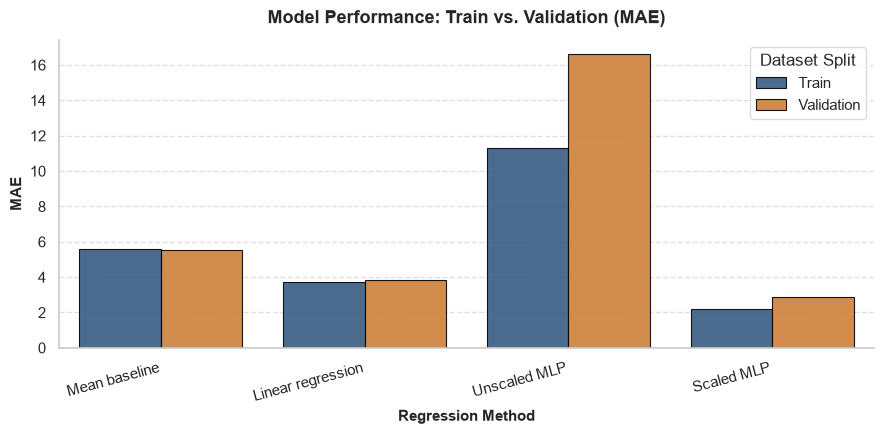

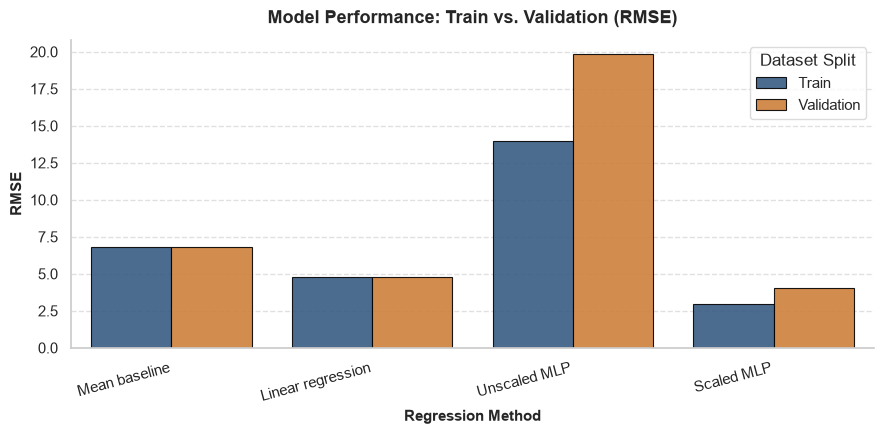

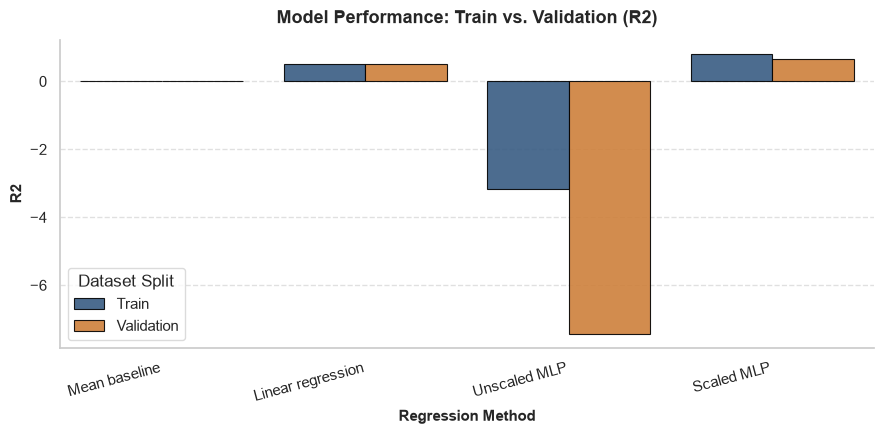

In [6]:
fig_numbers = {"MAE": "4.1", "RMSE": "4.2", "R2": "4.3"}

for m in metric_comparison_train.columns:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    plot_df = pd.DataFrame({"Train": metric_comparison_train[m], "Validation": metric_comparison_val[m]})
    melted_df = (plot_df.reset_index()
                 .rename(columns={"index": "Model"})
                 .melt(id_vars="Model", var_name="Dataset Split", value_name=m))

    sns.barplot(data=melted_df, x="Model", y=m, hue="Dataset Split",
                palette=["#2b5c8f", "#e67e22"], ax=ax, edgecolor="black", linewidth=0.8, alpha=0.9)

    ax.set_title(f"Model Performance: Train vs. Validation ({m})", fontsize=13, fontweight="bold", pad=12)
    ax.set_ylabel(m, fontsize=11, fontweight="bold")
    ax.set_xlabel("Regression Method", fontsize=11, fontweight="bold")
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
    ax.legend(title="Dataset Split", frameon=True, facecolor="white", edgecolor="lightgray")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    sns.despine(top=True, right=True)

    plt.tight_layout()
    fig.savefig(f"{FIG_DIR}/Figure_{fig_numbers[m]}_{m}_train_vs_validation.png", dpi=200, bbox_inches="tight")
    plt.show()

## 4. Validation: Group 10-fold Cross Validation
A single split can be lucky or unlucky, so the three remaining methods are re-tested on **10 different splits**.

**Procedure**
1. Divide the combined train + validation data (80% of the dataset) into 10 folds, keeping every group inside one fold.
2. Fit each method on 9 folds.
3. Predict the remaining fold and calculate MAE, RMSE and R².
4. Repeat until every fold has been the validation fold once.
5. Average the metrics over the 10 folds.

All methods use the same folds, and the MLP uses `START_WIDTH` = 20. The test set is **not** used here.

### 4.1 Run the cross-validation

In [7]:
gkf = GroupKFold(n_splits=N_FOLDS)
cv_splits = list(gkf.split(X_train_val, y_train_val, groups=groups[train_val_idx]))

fold_rows = []
for fold, (tr, va) in enumerate(cv_splits):
    X_tr, X_va = X_train_val.iloc[tr], X_train_val.iloc[va]
    y_tr, y_va = y_train_val.iloc[tr], y_train_val.iloc[va]

    # Whole groups stay in one fold
    assert set(groups[train_val_idx][tr]).isdisjoint(groups[train_val_idx][va])

    # fresh models for every fold
    for name, model in build_models(START_WIDTH).items():      
        model.fit(X_tr, y_tr)
        scores = regression_metrics(y_va, model.predict(X_va))
        fold_rows.append({"Fold": fold, "Model": name, **scores})

cv_results = pd.DataFrame(fold_rows)

print("---- Validation metrics for each fold ----")
display(cv_results.set_index(["Fold", "Model"]).unstack("Model").round(2))

---- Validation metrics for each fold ----


MAE                                       RMSE                                         R2                         
Model Linear regression Mean baseline Scaled MLP Linear regression Mean baseline Scaled MLP Linear regression Mean baseline Scaled MLP
Fold                                                                                                                                  
0                  3.50          5.59       2.54              4.48          6.64       3.64              0.55         -0.00       0.70
1                  3.75          5.40       3.18              4.69          6.74       4.38              0.51         -0.00       0.58
2                  3.22          5.05       2.59              4.11          6.31       3.34              0.56         -0.03       0.71
3                  3.41          5.72       2.29              4.43          6.91       3.04              0.59         -0.00       0.81
4                  3.30          5.07       3.06              4.48          6.29       4.07              0.49         -0.00       0.58
5                  3.93          5.72       7.94              5.13          7.14      11.42              0.48         -0.00      -1.56
6                  4.44          6.86       3.49              5.34          8.05       4.78              0.56         -0.01       0.64
7                  3.91          6.07       2.80              4.96          7.38       3.62              0.54         -0.01       0.76
8                  4.22          5.28       2.34              5.28          6.47       2.96              0.33         -0.01       0.79
9                  4.13          5.12       2.80              5.28          6.20       3.57              0.27         -0.00       0.67

### 4.2 Plot graph
Plot line graph to track the value of each metric at each fold.

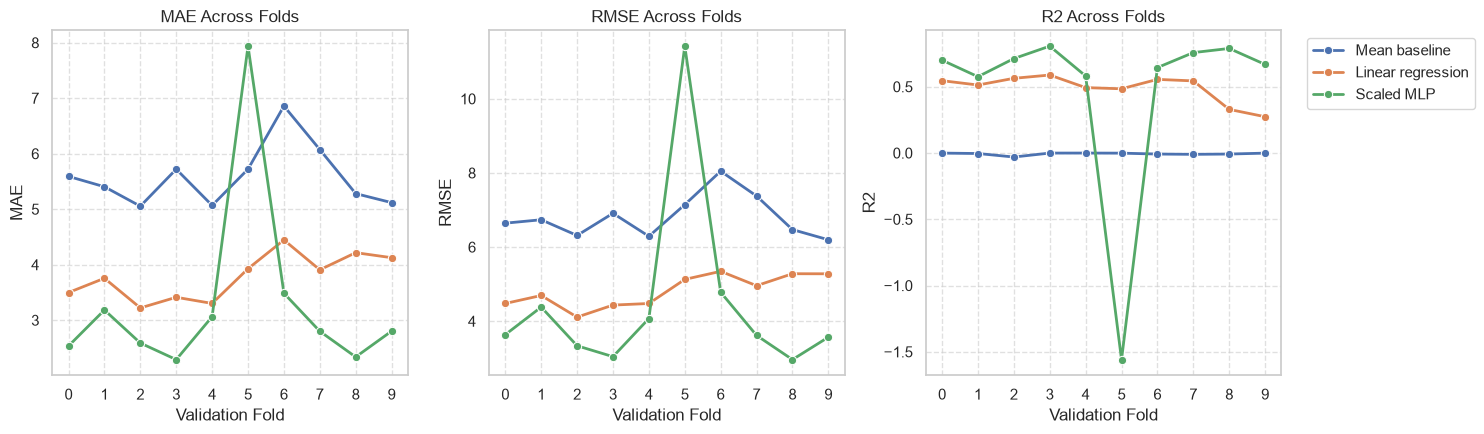

In [8]:
metrics = ["MAE", "RMSE", "R2"]
model_order = ["Mean baseline", "Linear regression", "Scaled MLP"]
model_colors = dict(zip(model_order, sns.color_palette("deep", 3)))   # same colour per model in every plot

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 4.5), sharex=True)

for ax, metric in zip(axes, metrics):
    sns.lineplot(data=cv_results, x="Fold", y=metric, hue="Model", hue_order=model_order,
                 palette=model_colors, marker="o", linewidth=2, ax=ax)
    ax.set_title(f"{metric} Across Folds")
    ax.set_xlabel("Validation Fold")
    ax.set_ylabel(metric)
    ax.set_xticks(range(N_FOLDS))
    ax.grid(True, linestyle="--", alpha=0.6)
    if metric == metrics[-1]:
        ax.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    else:
        ax.get_legend().remove()

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/figure_5.1_metrics_per_fold.png", dpi=200, bbox_inches="tight")
plt.show()

### 4.3 Average score
This section calcualates and plot the score of each metric averaging from the 10 fold. The bar is the mean over the 10 folds. The error bar is one standard deviation, which shows how much the result changes from fold to fold.

---- Mean over the 10 folds ----


,MAE,RMSE,R2
Model,,,
Mean baseline,5.59,6.81,-0.01
Linear regression,3.78,4.82,0.49
Scaled MLP,3.30,4.48,0.47


---- Standard deviation over the 10 folds ----


,MAE,RMSE,R2
Model,,,
Mean baseline,0.56,0.58,0.01
Linear regression,0.41,0.44,0.10
Scaled MLP,1.67,2.50,0.72


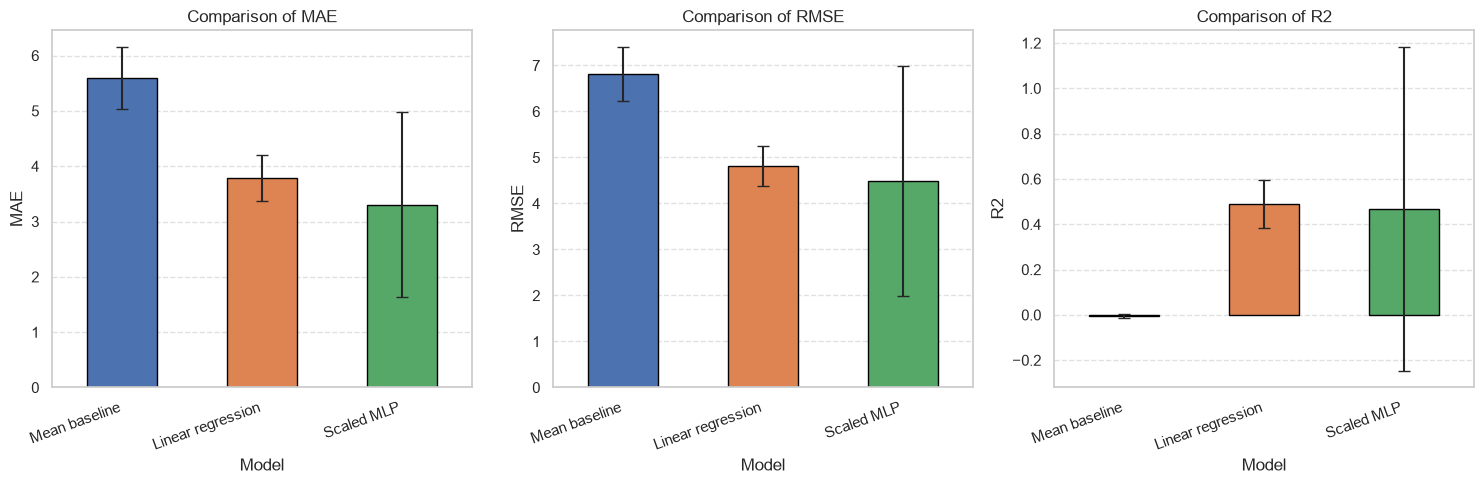

In [9]:
cv_mean = cv_results.groupby("Model")[metrics].mean().loc[model_order]
cv_std = cv_results.groupby("Model")[metrics].std().loc[model_order]

print("---- Mean over the 10 folds ----")
display(cv_mean.round(2))
print("---- Standard deviation over the 10 folds ----")
display(cv_std.round(2))

fig, axes = plt.subplots(1, len(metrics), figsize=(5 * len(metrics), 5))

for ax, metric in zip(axes, metrics):
    cv_mean[metric].plot(kind="bar", yerr=cv_std[metric], ax=ax, capsize=4,
                         color=[model_colors[m] for m in model_order], edgecolor="black")
    ax.set_title(f"Comparison of {metric}")
    ax.set_ylabel(metric)
    ax.set_xticklabels(cv_mean.index, rotation=20, ha="right")
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.grid(axis="x", visible=False)

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/figure_5.2_metrics_mean_std.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Optimization and performance
The scaled MLP is the best method so far, so one setting is tuned: the **hidden layer width** (number of neurons). Width controls both accuracy and cost.

**Procedure**
1. Choose the widths to test: 5, 10, 20, 50, 100.
2. For each width, run the same 10-fold group cross-validation as in Section 5.
3. In every fold, record the train RMSE, validation RMSE, validation R² and whether the MLP beats linear regression in terms of RMSE (a "win").
4. Average over the folds and compare the widths.

### 5.1 Width sweep

In [10]:
widths = [5, 10, 20, 50, 100]
sweep_rows = []

for fold, (tr, va) in enumerate(cv_splits):               
    X_tr, X_va = X_train_val.iloc[tr], X_train_val.iloc[va]
    y_tr, y_va = y_train_val.iloc[tr], y_train_val.iloc[va]

    # Linear regression on the same fold is the reference for this fold
    lr = LinearRegression().fit(X_tr, y_tr)
    lr_rmse = regression_metrics(y_va, lr.predict(X_va))["RMSE"]

    for w in widths:
        model_w = make_pipeline(StandardScaler(), make_mlp(hidden_layer_sizes=(w,)))
        model_w.fit(X_tr, y_tr)
        train_scores = regression_metrics(y_tr, model_w.predict(X_tr))
        val_scores = regression_metrics(y_va, model_w.predict(X_va))

        sweep_rows.append({
            "fold": fold, "width": w,
            "train_RMSE": train_scores["RMSE"],
            "val_RMSE": val_scores["RMSE"],
            "val_R2": val_scores["R2"],
            "lr_val_RMSE": lr_rmse,
        })

sweep_results = pd.DataFrame(sweep_rows)

# A "win" means the MLP has a lower validation RMSE than linear regression in that fold
sweep_results["beats_lr"] = sweep_results["val_RMSE"] < sweep_results["lr_val_RMSE"]

sweep_summary = sweep_results.groupby("width").agg(
    train_RMSE_mean=("train_RMSE", "mean"),
    val_RMSE_mean=("val_RMSE", "mean"),
    val_RMSE_std=("val_RMSE", "std"),
    val_R2_mean=("val_R2", "mean"),
    wins_vs_lr=("beats_lr", "sum"),
)
sweep_summary["parameters"] = [mlp_parameters(w) for w in sweep_summary.index]
sweep_summary["FLOPs"] = [mlp_flops(w) for w in sweep_summary.index]

print("---- Average over the 10 folds, for each hidden layer width ----")
display(sweep_summary.round(2))

print("---- Folds where the MLP lost to linear regression ----")
display(sweep_results.loc[~sweep_results["beats_lr"], ["fold", "width", "val_RMSE", "lr_val_RMSE"]].round(2))

---- Average over the 10 folds, for each hidden layer width ----


,train_RMSE_mean,val_RMSE_mean,val_RMSE_std,val_R2_mean,wins_vs_lr,parameters,FLOPs
width,,,,,,,
5,4.53,4.83,0.86,0.49,7,36,60
10,4.22,5.63,3.33,0.13,6,71,120
20,3.31,4.48,2.50,0.47,9,141,240
50,3.05,3.98,1.65,0.61,9,351,600
100,2.45,3.97,1.99,0.60,9,701,1200


---- Folds where the MLP lost to linear regression ----


,fold,width,val_RMSE,lr_val_RMSE
1,0,10,5.00,4.48
20,4,5,4.80,4.48
21,4,10,4.63,4.48
25,5,5,6.51,5.13
26,5,10,15.01,5.13
27,5,20,11.42,5.13
28,5,50,8.33,5.13
29,5,100,9.33,5.13
30,6,5,5.95,5.34
31,6,10,5.59,5.34


### 5.2 Plot Graph
Plot the RMSE score of different hidden layer width count. The shaded area represents one standard deviation range.


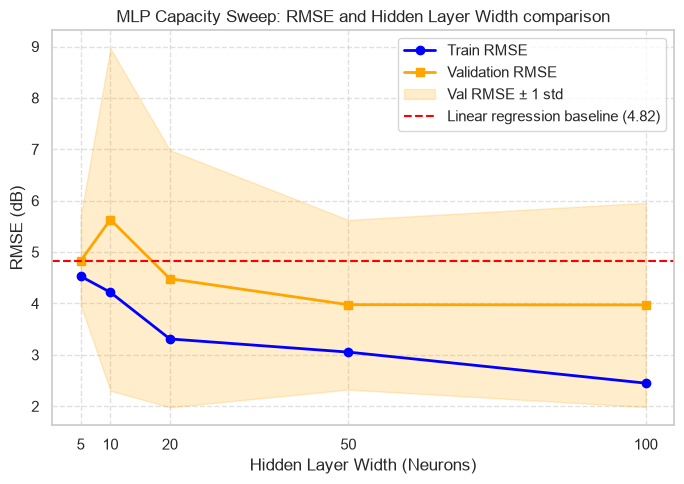

In [11]:
# ---- Figure 6.1: train and validation RMSE ----
fig1, ax1 = plt.subplots(figsize=(7, 5))

ax1.plot(sweep_summary.index, sweep_summary["train_RMSE_mean"],
         marker="o", label="Train RMSE", color="blue", linewidth=2)
ax1.plot(sweep_summary.index, sweep_summary["val_RMSE_mean"],
         marker="s", label="Validation RMSE", color="orange", linewidth=2)
ax1.fill_between(sweep_summary.index,
                 sweep_summary["val_RMSE_mean"] - sweep_summary["val_RMSE_std"],
                 sweep_summary["val_RMSE_mean"] + sweep_summary["val_RMSE_std"],
                 color="orange", alpha=0.2, label="Val RMSE ± 1 std")

mean_lr_rmse = sweep_results["lr_val_RMSE"].mean()
ax1.axhline(y=mean_lr_rmse, color="red", linestyle="--",
            label=f"Linear regression baseline ({mean_lr_rmse:.2f})")

ax1.set_title("MLP Capacity Sweep: RMSE and Hidden Layer Width comparison")
ax1.set_xlabel("Hidden Layer Width (Neurons)")
ax1.set_ylabel("RMSE (dB)")
ax1.set_xticks(sweep_summary.index)
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend(loc="upper right")
plt.tight_layout()
fig1.savefig(f"{FIG_DIR}/figure_6.1_rmse_vs_width.png", dpi=200, bbox_inches="tight")
plt.show()

Plot the coefficient of determination and fold wins 

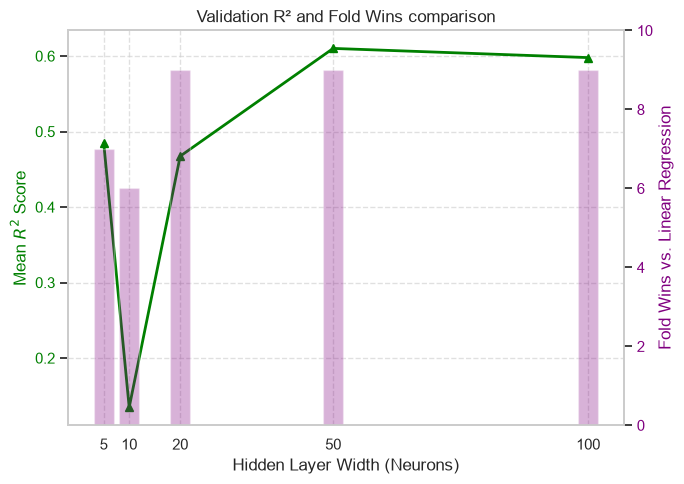

In [12]:
# ---- Figure 6.2: validation R2 and wins against linear regression ----
fig2, ax2 = plt.subplots(figsize=(7, 5))

ax2.plot(sweep_summary.index, sweep_summary["val_R2_mean"],
         marker="^", color="green", linewidth=2, label="Validation R²")
ax2.set_ylabel("Mean $R^2$ Score", color="green")
ax2.tick_params(axis="y", labelcolor="green")

ax3 = ax2.twinx()
ax3.bar(sweep_summary.index, sweep_summary["wins_vs_lr"],
        alpha=0.3, color="purple", width=4, label="Wins vs linear regression (out of 10 folds)")
ax3.set_ylabel("Fold Wins vs. Linear Regression", color="purple")
ax3.tick_params(axis="y", labelcolor="purple")
ax3.set_ylim(0, 10)
ax3.grid(False)

ax2.set_title("Validation R² and Fold Wins comparison")
ax2.set_xlabel("Hidden Layer Width (Neurons)")
ax2.set_xticks(sweep_summary.index)
ax2.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
fig2.savefig(f"{FIG_DIR}/figure_6.2_r2_and_wins_vs_width.png", dpi=200, bbox_inches="tight")
plt.show()

### 5.3 Computational cost
Since width of 50 and 100 performs relatively better, futher compare both these widths with the count of parameters and FLOPs per prediction.

In [13]:
size_rows = []
for w in [FINAL_WIDTH, 100]:
    pipe = make_pipeline(StandardScaler(), make_mlp(hidden_layer_sizes=(w,)))
    pipe.fit(X_train_val, y_train_val)
    size_rows.append({"Width": w,
                      "Parameters count": mlp_parameters(w),
                      "FLOPs per prediction": mlp_flops(w)})
display(pd.DataFrame(size_rows).set_index("Width"))

,Parameters count,FLOPs per prediction
Width,,
50,351,600
100,701,1200


## 6. Final Test
**Refit on train + validation (80%)** and evaluate **once** on the untouched test set (20%) among mean baseline, linear regression and neural network regression with scaled MLP (hidden layer width = `FINAL_WIDTH`)

### 6.1 Measure train and validation performance

In [14]:
# mean baseline, linear regression, scaled MLP (width 50)
final_models = build_models(FINAL_WIDTH)   

test_rows = {}
for name, model in final_models.items():
    # refit on train + validation
    model.fit(X_train_val, y_train_val)
    # evaluate once on the test set    
    test_rows[name] = regression_metrics(y_test, model.predict(X_test))   

results_df = pd.DataFrame(test_rows).T
results_df.index.name = "Model"

print(f"Test-set results (MLP width = {FINAL_WIDTH})")
display(results_df.round(2))

Test-set results (MLP width = 50)


,MAE,RMSE,R2
Model,,,
Mean baseline,5.68,7.15,-0.05
Linear regression,3.69,4.98,0.49
Scaled MLP,3.04,3.96,0.68


## 6.2 Measure computational cost
This section calculates the numer of parameters, FLOPs and runtime needed to train model and predict ddata.

In [3]:
# Number of parameters and FLOPs per prediction
cost_table = pd.DataFrame({
    "Parameters count": [0, 6, mlp_parameters(FINAL_WIDTH)],
    "FLOPs per prediction": [0, LINEAR_FLOPS, mlp_flops(FINAL_WIDTH)],
}, index=["Mean baseline", "Linear regression", f"Scaled MLP (width {FINAL_WIDTH})"])
display(cost_table)

,Parameters count,FLOPs per prediction
Mean baseline,0,0
Linear regression,6,10
Scaled MLP (width 50),351,600


In [16]:
# Training runtime
print("Time needed for training (fit on train + validation)")
%timeit DummyRegressor(strategy="mean").fit(X_train_val, y_train_val)
%timeit LinearRegression().fit(X_train_val, y_train_val)
%timeit build_models(FINAL_WIDTH)["Scaled MLP"].fit(X_train_val, y_train_val)

Time needed for training (fit on train + validation)
279 μs ± 12.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
1.97 ms ± 59.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
1.3 s ± 31.9 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [19]:
#Prediction runtime
print("Time needed for prediction (test set)")
%timeit final_models["Mean baseline"].predict(X_test)
%timeit final_models["Linear regression"].predict(X_test)
%timeit final_models["Scaled MLP"].predict(X_test)

Time needed for prediction (test set)
17.7 μs ± 404 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)
540 μs ± 11.3 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
1.07 ms ± 44.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
